<h1 style="color:red;">I. Exploration des données</h1>

In [1]:
#importation des bibliothèques nécessaires
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

### 1) Chargement des données

In [2]:
# Chargement du fichier Excel 
file_path = "BDD_IMG_IVG.xlsx"
df_img = pd.read_excel(file_path, sheet_name="IMG", header=1)
df_ivg = pd.read_excel(file_path, sheet_name="IVG", header=1) 

### 2) Description des données

<h4 style="color:red;">Fichier IMG :</h4>

Ce fichier regroupe les données des patientes ayant sollicité une Interruption Médicale de Grossesse (IMG), fondée sur des motifs maternels non somatiques. Il s’agit principalement de situations dans lesquelles la demande repose sur des facteurs psychologiques, sociaux ou physiques, sans présence de pathologie physique menaçant directement la santé de la mère.

<h4 style="color:red;">Fichier IVG :</h4>

Ce fichier rassemble les informations des patientes ayant eu recours à une Interruption Volontaire de Grossesse (IVG). Cela inclut des contextes variés, qu’ils soient personnels, sociaux, économiques ou médicaux.

## Données IVG

### 3) Aperçu général des données

In [3]:
# Afficher le nombre de lignes et de colonnes
print("Nombre de lignes :", df_ivg.shape[0])  
print("Nombre de colonnes :", df_ivg.shape[1])  

# Afficher le nom des colonnes
print("\nVariables présentes dans le dataset :")
print(df_ivg.columns.tolist())  

# Afficher les types de données de chaque colonne
print("\nTypes de données des colonnes :")
print(df_ivg.dtypes)

# Vérifier s'il y a des valeurs manquantes dans les colonnes
print("\nValeurs manquantes par colonne :")
print(df_ivg.isnull().sum())

# Afficher le pourcentage de valeurs manquantes
print("\nPourcentage de valeurs manquantes par colonne :")
print((df_ivg.isnull().mean() * 100).round(2).sort_values(ascending=False))

# Afficher les 10 premières lignes du dataset
df_ivg.head(10)

Nombre de lignes : 107
Nombre de colonnes : 29

Variables présentes dans le dataset :
['ivg_no_inclus', 'ivg_age', 'lieuvie_tot_ivg', 'profession_tot_ivg', 'statut_conj_simpl_ivg', 'enfant_charge_ivg', 'parcours_migratoire_ivg', 'pays_naiss_ivg', 'situation_administrative_ivg', 'atcd_violence_ivg', 'description_type_atcd_violences_ivg', 'contexte_atcd_violence_ivg', 'violences_actuelles_ivg', 'type_violence_actuelle_ivg', 'contexte_violence_actuelle_ivg', 'grossesse_issue_viol_ivg', 'violences_tot_ivg', 'gestite_ivg', 'parite_ivg', 'nbr_atcd_ivg_ivg', 'contraception_en_cours_ivg', 'echec_contraception_urg_ivg', 'grossesse_desire_ivg', 'date_decouverte_grossesse_ivg', 'date_debut_grossesse_ivg', 'nbr_jour_amenorrhée_découverte_ivg', 'date_ivg', 'terme_ivg', 'nja_ivg']

Types de données des colonnes :
ivg_no_inclus                                   int64
ivg_age                                         int64
lieuvie_tot_ivg                                 int64
profession_tot_ivg         

,ivg_no_inclus,ivg_age,lieuvie_tot_ivg,profession_tot_ivg,statut_conj_simpl_ivg,enfant_charge_ivg,parcours_migratoire_ivg,pays_naiss_ivg,situation_administrative_ivg,atcd_violence_ivg,...,nbr_atcd_ivg_ivg,contraception_en_cours_ivg,echec_contraception_urg_ivg,grossesse_desire_ivg,date_decouverte_grossesse_ivg,date_debut_grossesse_ivg,nbr_jour_amenorrhée_découverte_ivg,date_ivg,terme_ivg,nja_ivg
0,1,35,1,1,2,3,2,4,2,0,...,0,2,0,0,2020-10-02 00:00:00,2020-08-15,62,2020-10-12,10,72
1,2,21,1,2,1,0,2,7,1,1,...,1,0,0,0,2019-03-01 00:00:00,2019-01-20,54,2019-03-15,9,68
2,3,31,2,2,2,0,2,4,1,1,...,0,0,0,0,2018-08-21 00:00:00,2018-07-24,42,2018-09-12,9,64
3,4,36,1,1,1,4,0,1,3,0,...,1,2,0,0,2019-01-16 00:00:00,2018-12-12,49,2019-01-31,8,64
4,5,27,2,NR,1,1,0,1,3,1,...,0,0,0,0,NR,2018-12-28,NR,2019-03-22,14,98
5,6,17,1,2,1,0,1,7,2,1,...,0,0,0,0,2022-04-10 00:00:00,2022-03-20,35,2022-04-15,5,40
6,7,21,1,NR,2,0,0,1,3,0,...,0,0,0,0,2022-06-30 00:00:00,2022-06-06,38,2022-07-04,5,42
7,8,15,1,2,1,0,0,1,3,1,...,0,0,0,0,2019-05-16 00:00:00,2019-04-13,47,2019-06-12,10,74
8,9,41,1,2,2,3,0,1,3,0,...,0,2,0,0,2022-12-20 00:00:00,2022-11-28,36,2022-12-30,5,46
9,10,31,2,1,2,3,0,1,3,0,...,1,0,0,0,2019-01-10 00:00:00,2018-12-07,48,2019-01-10,7,48


<h5 style="color:red;">Remarque : Les résultats montrent qu’il n’y a pas de valeurs manquantes. En revanche, certaines colonnes sont de type object (texte), alors qu’elles devraient contenir uniquement des entiers. Cela est probablement dû à la présence de valeurs mixtes (texte et chiffres) au sein d’une même colonne.</h5>

### 4) Analyse des valeurs manquantes

*Pour cela, nous allons examiner les modalités présentes dans chaque colonne contenant à la fois du texte et des chiffres, afin d’identifier les éventuelles incohérences de format.*

In [4]:
# Nombre total de lignes (pour le calcul du %)
total = len(df_ivg)

# Parcourir les colonnes texte
for col in df_ivg.select_dtypes(include='object').columns:
    print(f"\n Colonne : {col}")
    print(" Valeurs uniques :", df_ivg[col].unique())

    # Nombre de "NR"
    nb_nr = (df_ivg[col] == "NR").sum()
    pct_nr = (nb_nr / total) * 100

    print(f" 'NR' : {nb_nr} valeurs ({pct_nr:.2f}%)")


 Colonne : profession_tot_ivg
 Valeurs uniques : [1 2 'NR']
 'NR' : 9 valeurs (8.41%)

 Colonne : pays_naiss_ivg
 Valeurs uniques : [4 7 1 23 24 25 2 5 26 12 13 3 27 28 21 8 29 30 'NR' 31 19 32 33]
 'NR' : 1 valeurs (0.93%)

 Colonne : situation_administrative_ivg
 Valeurs uniques : [2 1 3 'NR']
 'NR' : 2 valeurs (1.87%)

 Colonne : description_type_atcd_violences_ivg
 Valeurs uniques : [0 3 1 'NR' '1+2+3' '1+2']
 'NR' : 2 valeurs (1.87%)

 Colonne : contexte_atcd_violence_ivg
 Valeurs uniques : [0 7 5 1 'NR' '1+2' 2]
 'NR' : 3 valeurs (2.80%)

 Colonne : violences_actuelles_ivg
 Valeurs uniques : [0 1 'NR']
 'NR' : 1 valeurs (0.93%)

 Colonne : type_violence_actuelle_ivg
 Valeurs uniques : [0 '1 + 2' 1]
 'NR' : 0 valeurs (0.00%)

 Colonne : date_decouverte_grossesse_ivg
 Valeurs uniques : [datetime.datetime(2020, 10, 2, 0, 0) datetime.datetime(2019, 3, 1, 0, 0)
 datetime.datetime(2018, 8, 21, 0, 0) datetime.datetime(2019, 1, 16, 0, 0)
 'NR' datetime.datetime(2022, 4, 10, 0, 0)
 datet

<h5 style="color:red;"> On peut remarquer la présence de données manquantes notées "NR" dans certaines colonnes numériques. De plus, plusieurs modalités apparaissent parfois regroupées dans une même cellule, comme par exemple : "1+2+3", ce qui nécessite un traitement particulier pour les futures analyses. </h5>

### 5) Nettoyage des données

In [5]:
# Colonnes à exploser
colonnes_multi = [
    "description_type_atcd_violences_ivg",
    "contexte_atcd_violence_ivg",
    "type_violence_actuelle_ivg"
]

# Nettoyage + split + explode successif
for col in colonnes_multi:
    df_ivg[col] = df_ivg[col].astype(str).str.replace(" ", "").str.split("+")
    df_ivg = df_ivg.explode(col)

# Affichage d’un extrait
print(df_ivg[["ivg_no_inclus",
                    "description_type_atcd_violences_ivg",
                    "contexte_atcd_violence_ivg",
                    "type_violence_actuelle_ivg"]].head(20))

    ivg_no_inclus description_type_atcd_violences_ivg  \
0               1                                   0   
1               2                                   3   
2               3                                   1   
3               4                                   0   
4               5                                   1   
5               6                                  NR   
6               7                                   0   
7               8                                   3   
8               9                                   0   
9              10                                   0   
9              10                                   0   
10             11                                   0   
11             12                                   0   
12             13                                   0   
13             14                                  NR   
14             15                                   0   
15             16              

In [6]:
# Créer une fonction qui garde une seule valeur par ivg_no_inclus et laisse vide les autres
def remove_duplicates(df_ivg):
    df_unique = df_ivg.groupby('ivg_no_inclus', as_index=False).first()
    
    # Remplir les valeurs vides (NaN) avec un espace vide 
    df_unique = df_unique.fillna('')
    
    return df_unique

# Appliquer la fonction au DataFrame
df_cleaned = remove_duplicates(df_ivg)

# Afficher le résultat
print(df_cleaned[["ivg_no_inclus", 
                  "description_type_atcd_violences_ivg", 
                  "contexte_atcd_violence_ivg", 
                  "type_violence_actuelle_ivg"]].head(20))

    ivg_no_inclus description_type_atcd_violences_ivg  \
0               1                                   0   
1               2                                   3   
2               3                                   1   
3               4                                   0   
4               5                                   1   
5               6                                  NR   
6               7                                   0   
7               8                                   3   
8               9                                   0   
9              10                                   0   
10             11                                   0   
11             12                                   0   
12             13                                   0   
13             14                                  NR   
14             15                                   0   
15             16                                   1   
16             17              

In [36]:
# Remplacer 'NR' par NaN dans les colonnes concernées
df_ivg.replace("NR", np.nan, inplace=True)

# Conversion en date
df_ivg["date_decouverte_grossesse_ivg"] = pd.to_datetime(df_ivg["date_decouverte_grossesse_ivg"], errors='coerce')

# Conversion en numériques entiers 
colonnes_entiers = [
    "description_type_atcd_violences_ivg",
    "type_violence_actuelle_ivg",
    "contexte_atcd_violence_ivg",
    "profession_tot_ivg",
    "pays_naiss_ivg",
    "situation_administrative_ivg",
    "violences_actuelles_ivg"
]
df_ivg[colonnes_entiers] = df_ivg[colonnes_entiers].apply(pd.to_numeric, errors='coerce').astype("Int64")

<h5 style="color:red;"> Pour le nettoyage des données, j’ai remplacé les valeurs "NR" par NaN, et pour les colonnes contenant plusieurs modalités dans une même cellule (par exemple "1+2+3"), j’ai séparé ces modalités et dupliqué les lignes correspondantes à l’aide de la méthode explode. </h5>

In [8]:
# Afficher les types de données de chaque colonne
print("\nTypes de données des colonnes :")
print(df_ivg.dtypes)


Types de données des colonnes :
ivg_no_inclus                                   int64
ivg_age                                         int64
lieuvie_tot_ivg                                 int64
profession_tot_ivg                              Int64
statut_conj_simpl_ivg                           int64
enfant_charge_ivg                               int64
parcours_migratoire_ivg                         int64
pays_naiss_ivg                                  Int64
situation_administrative_ivg                    Int64
atcd_violence_ivg                               int64
description_type_atcd_violences_ivg             Int64
contexte_atcd_violence_ivg                      Int64
violences_actuelles_ivg                         Int64
type_violence_actuelle_ivg                      Int64
contexte_violence_actuelle_ivg                  int64
grossesse_issue_viol_ivg                        int64
violences_tot_ivg                               int64
gestite_ivg                                     i

In [9]:
# Fichier IVG néttoyé
df_ivg.to_excel("IVG_nettoye.xlsx", index=False)

In [10]:
# Chargement du fichier nettoyé
df_ivg = pd.read_excel("IVG_nettoye.xlsx")

### 6) Analyse des valeurs aberrantes ( distribution des variables et statistiques)

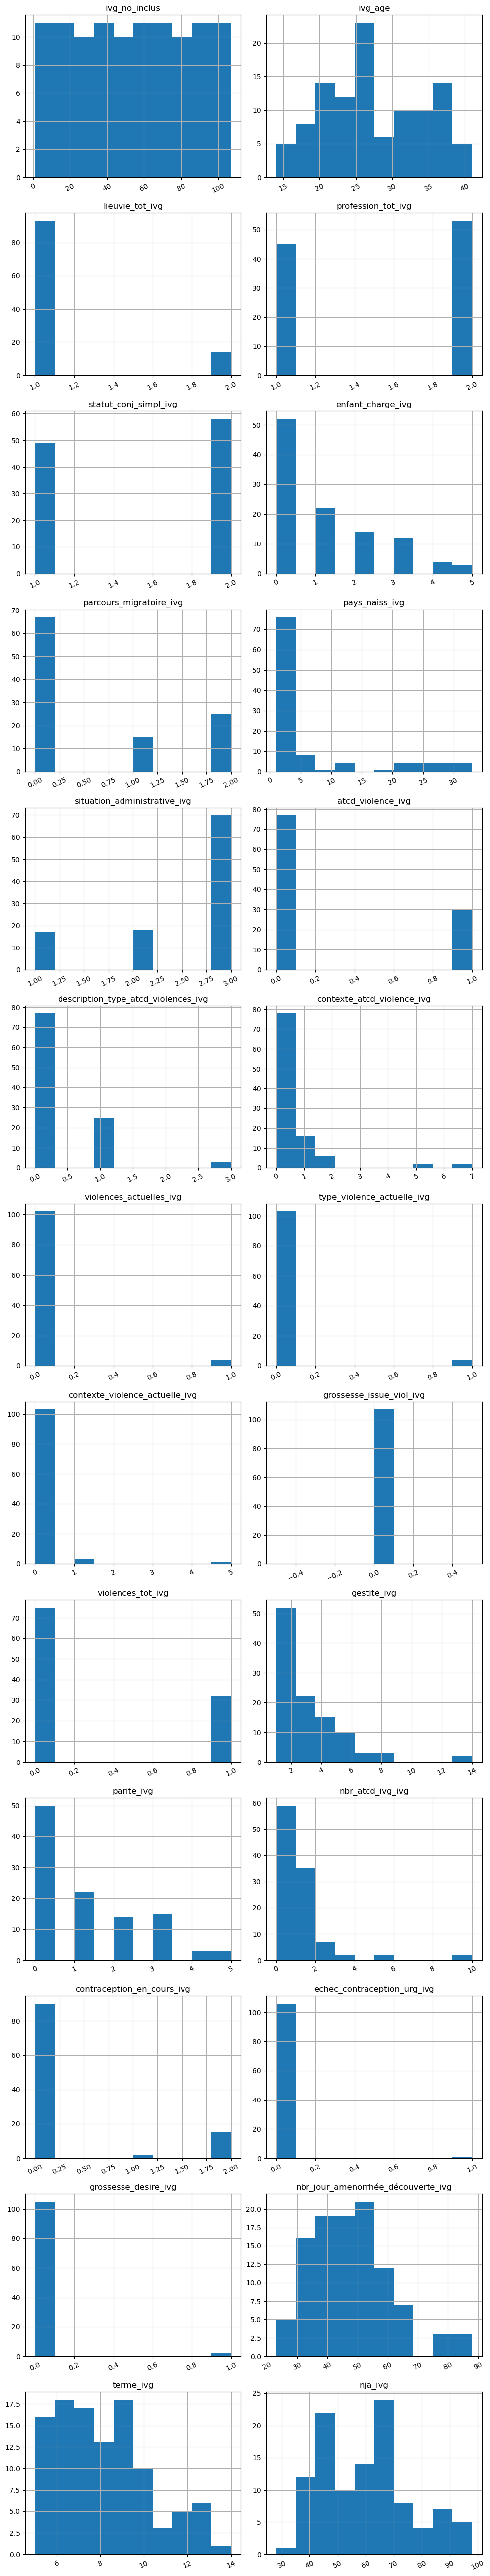

In [11]:
# Colonnes numériques
cols = df_ivg.select_dtypes(include='number').columns

# Supprimer les doublons sur ivg_no_inclus
df_unique = df_ivg.drop_duplicates(subset='ivg_no_inclus')

# Nombre de lignes à afficher (2 histogrammes par ligne)
n = len(cols)
rows = math.ceil(n / 2)

# Affichage des histogrammes
df_unique[cols].hist(layout=(rows, 2), figsize=(10, rows * 4), xrot=25)
plt.tight_layout()
plt.show()

In [12]:
# On enlève les doublons sur 'ivg_no_inclus' et garde le premier
df_ivg_unique = df_ivg.drop_duplicates(subset='ivg_no_inclus')

### 7) Analyse des corrélations

In [13]:
# Statistiques récapitulatives des caractéristiques numériques
df_ivg_unique.describe()

,ivg_no_inclus,ivg_age,lieuvie_tot_ivg,profession_tot_ivg,statut_conj_simpl_ivg,enfant_charge_ivg,parcours_migratoire_ivg,pays_naiss_ivg,situation_administrative_ivg,atcd_violence_ivg,...,nbr_atcd_ivg_ivg,contraception_en_cours_ivg,echec_contraception_urg_ivg,grossesse_desire_ivg,date_decouverte_grossesse_ivg,date_debut_grossesse_ivg,nbr_jour_amenorrhée_découverte_ivg,date_ivg,terme_ivg,nja_ivg
count,107.000000,107.000000,107.000000,98.000000,107.000000,107.000000,107.000000,106.000000,105.000000,107.000000,...,107.000000,107.000000,107.000000,107.000000,105,107,105.000000,107,107.000000,107.000000
mean,54.000000,27.485981,1.130841,1.540816,1.542056,1.093458,0.607477,6.066038,2.504762,0.280374,...,0.785047,0.299065,0.009346,0.018692,2020-10-08 05:42:51.428571392,2020-08-29 08:04:29.158878464,47.485714,2020-10-13 16:49:20.747663616,8.018692,59.364486
min,1.000000,14.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,2017-10-05 00:00:00,2017-08-18 00:00:00,23.000000,2017-10-12 00:00:00,5.000000,28.000000
25%,27.500000,22.500000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,2.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,2019-10-29 00:00:00,2019-09-18 00:00:00,37.000000,2019-11-05 12:00:00,6.000000,45.500000
50%,54.000000,27.000000,1.000000,2.000000,2.000000,1.000000,0.000000,1.000000,3.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,2020-08-25 00:00:00,2020-07-14 00:00:00,46.000000,2020-09-01 00:00:00,8.000000,59.000000
75%,80.500000,33.500000,1.000000,2.000000,2.000000,2.000000,1.000000,5.000000,3.000000,1.000000,...,1.000000,0.000000,0.000000,0.000000,2021-12-15 00:00:00,2021-11-10 12:00:00,55.000000,2021-12-20 00:00:00,9.000000,68.500000
max,107.000000,41.000000,2.000000,2.000000,2.000000,5.000000,2.000000,33.000000,3.000000,1.000000,...,10.000000,2.000000,1.000000,1.000000,2023-05-17 00:00:00,2023-04-10 00:00:00,88.000000,2023-05-23 00:00:00,14.000000,98.000000
std,31.032241,6.832724,0.338813,0.500893,0.500573,1.363491,0.844036,9.309768,0.761120,0.451296,...,1.523576,0.703294,0.096674,0.136071,NaN,NaN,13.105426,NaN,2.347143,16.022621


In [14]:
#Calcul de la matrice de corrélation
corrs = df_ivg_unique.select_dtypes(include='number').corr()
corrs

,ivg_no_inclus,ivg_age,lieuvie_tot_ivg,profession_tot_ivg,statut_conj_simpl_ivg,enfant_charge_ivg,parcours_migratoire_ivg,pays_naiss_ivg,situation_administrative_ivg,atcd_violence_ivg,...,violences_tot_ivg,gestite_ivg,parite_ivg,nbr_atcd_ivg_ivg,contraception_en_cours_ivg,echec_contraception_urg_ivg,grossesse_desire_ivg,nbr_jour_amenorrhée_découverte_ivg,terme_ivg,nja_ivg
ivg_no_inclus,1.000000,0.005695,-0.164199,-0.062484,0.175514,0.011148,0.106613,0.246572,-0.179279,-0.150219,...,-0.200246,0.063917,0.046619,0.051081,-0.212239,-0.059748,0.031278,-0.082965,-0.014895,-0.032179
ivg_age,0.005695,1.000000,0.102678,-0.093149,0.134639,0.489239,0.167528,0.120975,-0.223982,0.022703,...,0.058375,0.474876,0.530548,0.208593,0.159900,-0.106916,-0.009862,-0.135432,-0.167634,-0.210773
lieuvie_tot_ivg,-0.164199,0.102678,1.000000,0.009406,0.022874,0.054965,-0.016649,-0.005787,-0.039452,0.251406,...,0.291337,0.011554,0.041624,-0.018105,-0.165764,-0.037685,-0.053548,0.074680,0.103663,0.072809
profession_tot_ivg,-0.062484,-0.093149,0.009406,1.000000,-0.001672,0.200419,0.068064,0.037064,-0.198343,0.109904,...,0.059050,0.099923,0.190176,-0.047616,-0.093551,0.093558,-0.011822,0.054580,0.061741,0.132307
statut_conj_simpl_ivg,0.175514,0.134639,0.022874,-0.001672,1.000000,0.173875,0.039441,0.010692,-0.031922,-0.261491,...,-0.259987,0.194132,0.164127,0.104739,-0.089658,-0.105673,-0.150154,-0.106541,-0.161265,-0.242469
enfant_charge_ivg,0.011148,0.489239,0.054965,0.200419,0.173875,1.000000,0.146942,0.141241,-0.231061,-0.042985,...,-0.014901,0.792876,0.947289,0.277697,-0.019584,-0.078259,-0.111201,-0.076340,-0.030029,-0.057279
parcours_migratoire_ivg,0.106613,0.167528,-0.016649,0.068064,0.039441,0.146942,1.000000,0.683035,-0.803979,-0.079856,...,-0.107865,0.219628,0.179502,0.161190,-0.022874,-0.070235,0.228771,0.139401,0.094217,0.102063
pays_naiss_ivg,0.246572,0.120975,-0.005787,0.037064,0.010692,0.141241,0.683035,1.000000,-0.683433,-0.171735,...,-0.190985,0.039342,0.151790,-0.110770,-0.049428,-0.053357,0.141193,0.120020,0.076066,0.111217
situation_administrative_ivg,-0.179279,-0.223982,-0.039452,-0.198343,-0.031922,-0.231061,-0.803979,-0.683433,1.000000,0.079518,...,0.105095,-0.341037,-0.263696,-0.270542,0.193344,0.064109,-0.092856,-0.171462,-0.046027,-0.085436
atcd_violence_ivg,-0.150219,0.022703,0.251406,0.109904,-0.261491,-0.042985,-0.079856,-0.171735,0.079518,1.000000,...,0.955588,-0.029510,0.012184,-0.089888,-0.088336,-0.060626,-0.086146,0.029256,0.173130,0.165778


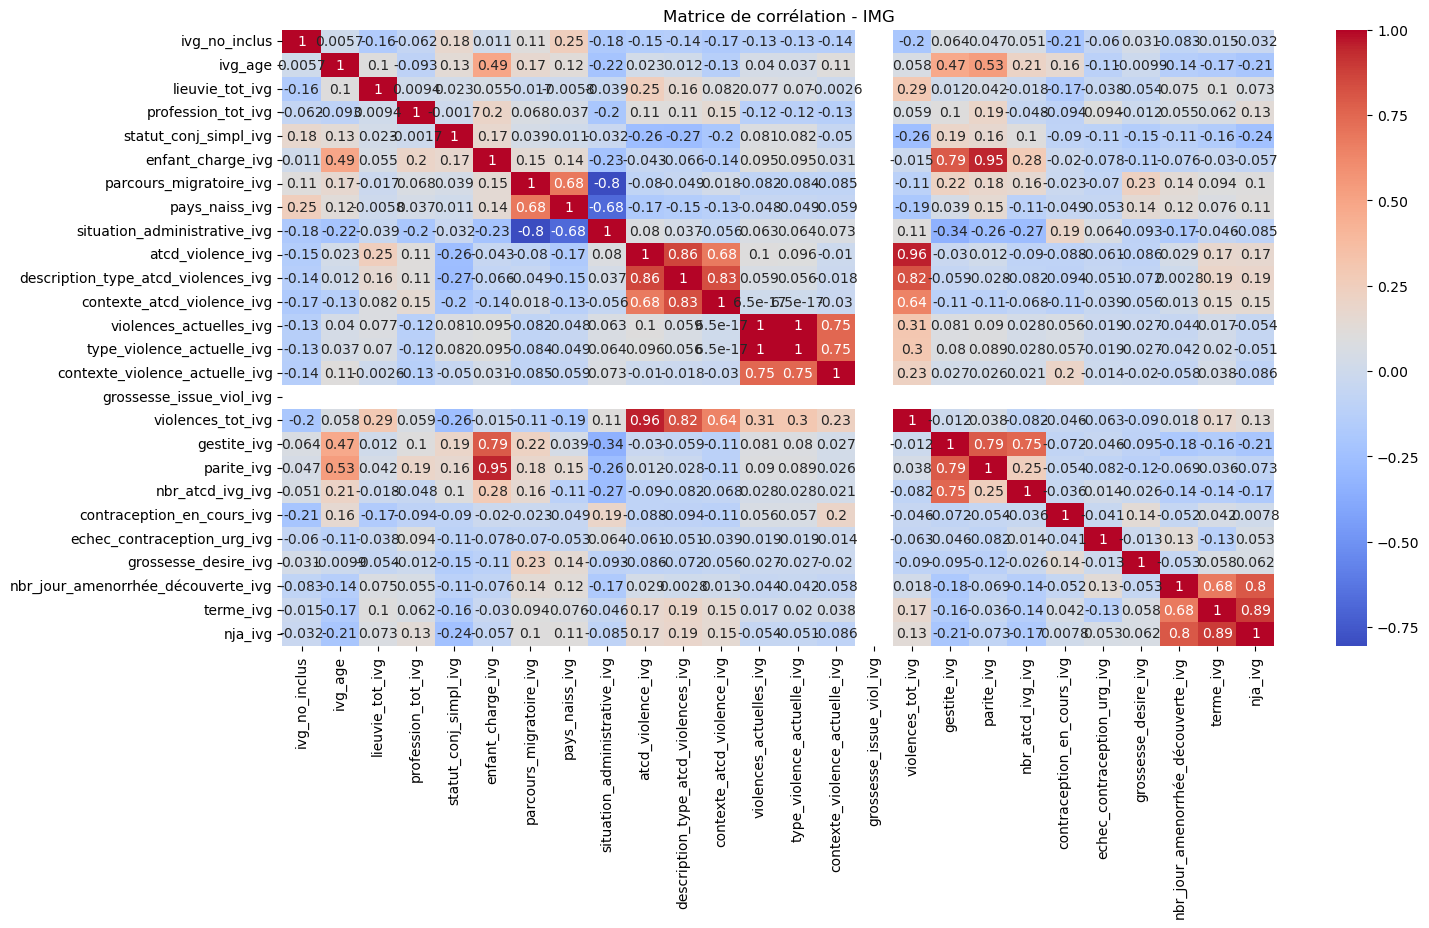

In [15]:
#Affichage de la Heatmap
plt.figure(figsize=(16, 8))
sns.heatmap(corrs, annot=True, cmap='coolwarm')
plt.title("Matrice de corrélation - IMG")
plt.show()

In [16]:
# Filtrage des corrélations supérieures à 0.5 (hors diagonale)
high_corr = corrs.where(np.triu(np.ones(corrs.shape), k=1).astype(bool))
high_corr_filtered = high_corr[(high_corr.abs() > 0.5)]

# Récupération des couples de variables concernées
result = high_corr_filtered.stack().reset_index()
result.columns = ['Variable 1', 'Variable 2', 'Corrélation']

# Affichage
print(result)

                             Variable 1                           Variable 2  \
0                               ivg_age                           parite_ivg   
1                     enfant_charge_ivg                          gestite_ivg   
2                     enfant_charge_ivg                           parite_ivg   
3               parcours_migratoire_ivg                       pays_naiss_ivg   
4               parcours_migratoire_ivg         situation_administrative_ivg   
5                        pays_naiss_ivg         situation_administrative_ivg   
6                     atcd_violence_ivg  description_type_atcd_violences_ivg   
7                     atcd_violence_ivg           contexte_atcd_violence_ivg   
8                     atcd_violence_ivg                    violences_tot_ivg   
9   description_type_atcd_violences_ivg           contexte_atcd_violence_ivg   
10  description_type_atcd_violences_ivg                    violences_tot_ivg   
11           contexte_atcd_violence_ivg 

## Données IMG

### 3) Aperçu général des données

In [17]:
# Afficher le nombre de lignes et de colonnes
print("Nombre de lignes :", df_img.shape[0])  
print("Nombre de colonnes :", df_img.shape[1])  

# Afficher le nom des colonnes
print("\nVariables présentes dans le dataset :")
print(df_ivg.columns.tolist())  

# Afficher les types de données de chaque colonne
print("\nTypes de données des colonnes :")
print(df_img.dtypes)

# Vérifier s'il y a des valeurs manquantes dans les colonnes
print("\nValeurs manquantes par colonne :")
print(df_img.isnull().sum())

# Afficher le pourcentage de valeurs manquantes
print("\nPourcentage de valeurs manquantes par colonne :")
print((df_img.isnull().mean() * 100).round(2).sort_values(ascending=False))

# Afficher les 10 premières lignes du dataset
df_img.head(10)

Nombre de lignes : 107
Nombre de colonnes : 44

Variables présentes dans le dataset :
['ivg_no_inclus', 'ivg_age', 'lieuvie_tot_ivg', 'profession_tot_ivg', 'statut_conj_simpl_ivg', 'enfant_charge_ivg', 'parcours_migratoire_ivg', 'pays_naiss_ivg', 'situation_administrative_ivg', 'atcd_violence_ivg', 'description_type_atcd_violences_ivg', 'contexte_atcd_violence_ivg', 'violences_actuelles_ivg', 'type_violence_actuelle_ivg', 'contexte_violence_actuelle_ivg', 'grossesse_issue_viol_ivg', 'violences_tot_ivg', 'gestite_ivg', 'parite_ivg', 'nbr_atcd_ivg_ivg', 'contraception_en_cours_ivg', 'echec_contraception_urg_ivg', 'grossesse_desire_ivg', 'date_decouverte_grossesse_ivg', 'date_debut_grossesse_ivg', 'nbr_jour_amenorrhée_découverte_ivg', 'date_ivg', 'terme_ivg', 'nja_ivg']

Types de données des colonnes :
no_inclus                                       int64
age_img                                         int64
lieuvie_tot_img                                 int64
profession_simpl_img       

,no_inclus,age_img,lieuvie_tot_img,profession_simpl_img,Statut_conj_simplifié_img,enfant_charge_img,parcours_migratoire_img,pays_naiss_img,situation_administrative_img,atcd_violence_img,...,date_1ere_cs_centre_img,terme_1ere_cs_centre_img,nja_1ere_cs_centre_img,decision_pluridisciplinaire_img,date_img,terme_img,nja_img,lieu_img,parcours,img
0,1,22,1,2,2,0,0,1,3,0,...,2019-09-15,17SA+2j,121,1,2019-09-26 00:00:00,18SA+6j,132.0,1,oui,oui
1,2,16,1,2,1,0,1,2,3,0,...,2019-09-27,17SA+3j,122,NaN,NaN,NaN,NaN,NaN,sortie,0
2,3,16,2,2,1,0,NR,NR,NR,NR,...,2019-10-07,20SA+0j,140,1,2019-10-21 00:00:00,22SA+0j,154.0,1,oui,oui
3,4,29,1,NR,1,2,0,1,3,NR,...,2022-01-11,15SA+5j,110,NaN,NaN,NaN,NaN,NaN,sortie,0
4,5,18,2,2,1,0,0,1,3,1,...,2020-05-07,17SA+4j,123,1,2020-05-15 00:00:00,18SA+5j,131.0,3,oui,oui
5,6,17,1,2,1,0,0,1,3,0,...,2019-07-08,20SA+0j,140,1,2019-07-20 00:00:00,21SA+5j,152.0,1,oui,oui
6,7,33,1,NR,2,2,2,12,3,NR,...,2021-05-20,13SA+3j,94,1,NaN,NaN,NaN,NaN,oui,changement
7,8,23,2,2,2,0,0,1,3,0,...,2021-08-05,17SA+6j,125,1,2021-08-13 00:00:00,19SA+0j,133.0,4,oui,oui
8,9,22,1,1,1,0,2,4,2,1,...,2019-09-03,28SA+3j,199,1,2019-09-26 00:00:00,31SA+5j,222.0,1,oui,oui
9,10,19,1,NR,1,0,0,1,3,NR,...,2020-05-19,15SA+0j,105,NaN,NaN,NaN,NaN,NaN,sortie,0


<h5 style="color:red;">On remarque que certaines colonnes contiennent des valeurs manquantes (vides) et que, comme dans le fichier IVG, plusieurs colonnes sont de type object (texte), alors qu’elles devraient être de type numérique. Cela est probablement dû à la présence de chaînes de caractères comme "NR" ou à un mélange de texte et de chiffres dans les mêmes colonnes.</h5>

### 4) Analyse des valeurs manquantes

*Pour cela, nous allons examiner les modalités présentes dans chaque colonne contenant à la fois du texte et des chiffres, afin d’identifier les éventuelles incohérences de format.*

In [18]:
# Liste des colonnes à analyser
colonnes = [
    "profession_simpl_img", "parcours_migratoire_img", "pays_naiss_img",
    "situation_administrative_img", "atcd_violence_img", "description_type_atcd_violences_img",
    "contexte_atcd_violence_img", "violences_actuelles_img", "type_violence_actuelle_img",
    "contexte_violence_actuelle_img", "grossesse_issue_viol_img", "nbr_atcd_ivg_img",
    "contraception_en_cours_img", "echec_contraception_urg_img", "grossesse_desire_img",
    "cycles_regluliers_img", "date_decouverte_grossesse_img", "terme_decouverte_grossesse_img",
    "nbr_jour_amenorrhée_découverte_img", "date_1ere_echo_img", "terme_1ere_echo_img",
    "nja_1ere_echo_img", "date_1ere_demande_img", "terme_1ere_demande_img", "nja_1ere_demande_img",
    "decision_pluridisciplinaire_img", "date_img", "terme_img", "nja_img", "lieu_img"
]

# Afficher modalités et pourcentages
for col in colonnes:
    print(f"\n Colonne : {col}")
    valeurs = df_img[col].astype(str).str.strip().fillna("NaN")
    freqs = valeurs.value_counts(dropna=False)
    pourcents = valeurs.value_counts(normalize=True, dropna=False) * 100

    for val in freqs.index:
        print(f"  '{val}' : {freqs[val]} ({pourcents[val]:.2f}%)")


 Colonne : profession_simpl_img
  '2' : 64 (59.81%)
  '1' : 26 (24.30%)
  'NR' : 17 (15.89%)

 Colonne : parcours_migratoire_img
  '0' : 54 (50.47%)
  '2' : 27 (25.23%)
  '1' : 23 (21.50%)
  'NR' : 3 (2.80%)

 Colonne : pays_naiss_img
  '1' : 55 (51.40%)
  '7' : 7 (6.54%)
  'NR' : 5 (4.67%)
  '4' : 5 (4.67%)
  '12' : 4 (3.74%)
  '10' : 4 (3.74%)
  '2' : 3 (2.80%)
  '19' : 3 (2.80%)
  '3' : 3 (2.80%)
  '6' : 2 (1.87%)
  '5' : 2 (1.87%)
  '13' : 2 (1.87%)
  '16' : 2 (1.87%)
  '9' : 1 (0.93%)
  '8' : 1 (0.93%)
  '20' : 1 (0.93%)
  '14' : 1 (0.93%)
  '11' : 1 (0.93%)
  '15' : 1 (0.93%)
  '17' : 1 (0.93%)
  '18' : 1 (0.93%)
  '21' : 1 (0.93%)
  '22' : 1 (0.93%)

 Colonne : situation_administrative_img
  '3' : 67 (62.62%)
  '2' : 17 (15.89%)
  '1' : 13 (12.15%)
  'NR' : 9 (8.41%)
  '4' : 1 (0.93%)

 Colonne : atcd_violence_img
  '1' : 52 (48.60%)
  '0' : 43 (40.19%)
  'NR' : 12 (11.21%)

 Colonne : description_type_atcd_violences_img
  '0' : 43 (40.19%)
  '1 + 2 + 3' : 13 (12.15%)
  '1 + 2'

<h5 style="color:red;"> On peut remarquer la présence de valeurs manquantes, représentées sous différentes formes comme des cellules vides, des "NR" ou des "NA". Certaines colonnes contiennent également un mélange de texte et de chiffres, voire uniquement du texte, alors qu’elles devraient contenir des valeurs numériques. </h5>

### 5) Nettoyage des données

In [19]:
# Remplacement dans la colonne 'description_type_atcd_violences_img'
df_img['description_type_atcd_violences_img'] = df_img['description_type_atcd_violences_img'].replace({
    '1+2+4 + prostitution': '1+2+4+7',
    'ASE ds l\'enfance + fugues': '6'
})

# Remplacement dans la colonne 'contexte_atcd_violence_img'
df_img['contexte_atcd_violence_img'] = df_img['contexte_atcd_violence_img'].replace({
    '7 (dans un gang, drogue + prostitution)': '7',
    'ASE ds l\'enfance + fugues': '8'
})

In [20]:
# Nettoyage de la colonne nbr_atcd_ivg_img
df_img['nbr_atcd_ivg_img'] = df_img['nbr_atcd_ivg_img'].replace({
    '1 IMG': '1',
    '1 IMG foetale': '1',
    'nan': np.nan
})

In [21]:
# Nettoyage de la colonne echec_contraception_urg_img
df_img['echec_contraception_urg_img'] = df_img['echec_contraception_urg_img'].replace({
    'echec IVG': '2',
    'echec IVG med': '2',
    'nan': np.nan
})

In [22]:
# La colonne IMG ( oui  à été remplacé par 1 pour ceux ayant réalisé et 0 le reste (non,hollande,changement,perdu)

In [35]:
# Remplacer 'NR' par NaN dans les colonnes concernées
df_img.replace("NR", np.nan, inplace=True)

In [24]:
# Conversion en numériques entiers
colonnes_a_convertir = [
    'profession_simpl_img',
    'parcours_migratoire_img',
    'pays_naiss_img',
    'situation_administrative_img',
    'grossesse_issue_viol_img',
    'nbr_atcd_ivg_img',
    'contraception_en_cours_img',
    'echec_contraception_urg_img',
    'grossesse_desire_img',
    'cycles_regluliers_img',
    'nbr_jour_amenorrhée_découverte_img',
    'nja_1ere_echo_img',
    'nja_1ere_demande_img',
    'decision_pluridisciplinaire_img',
    'nja_img',
    'lieu_img',
    'atcd_violence_img',                          
    'description_type_atcd_violences_img',            
    'contexte_atcd_violence_img',                   
    'violences_actuelles_img',                        
    'type_violence_actuelle_img',                     
    'contexte_violence_actuelle_img'
]

for col in colonnes_a_convertir:
    df_img[col] = pd.to_numeric(df_img[col], errors='coerce').astype('Int64')

In [25]:
# vérification des types de données après nettoyage
df_img.dtypes

no_inclus                                       int64
age_img                                         int64
lieuvie_tot_img                                 int64
profession_simpl_img                            Int64
Statut_conj_simplifié_img                       int64
enfant_charge_img                               int64
parcours_migratoire_img                         Int64
pays_naiss_img                                  Int64
situation_administrative_img                    Int64
atcd_violence_img                               Int64
description_type_atcd_violences_img             Int64
contexte_atcd_violence_img                      Int64
violences_actuelles_img                         Int64
type_violence_actuelle_img                      Int64
contexte_violence_actuelle_img                  Int64
grossesse_issue_viol_img                        Int64
violences_tot_img                               int64
gestite_img                                     int64
parite_img                  

<h5 style="color:red;">J’ai procédé au nettoyage des données en remplaçant les valeurs "NA" et "NR" par NaN. J’ai ensuite utilisé la méthode explode() pour dupliquer les lignes lorsque plusieurs modalités étaient présentes dans une même cellule, et j’ai séparé les modalités exprimées sous forme de texte afin de pouvoir les analyser individuellement. </h5>

In [26]:
# Fichier IMG néttoyé
df_img.to_excel("IMG_nettoye.xlsx", index=False)

In [27]:
# Chargement du fichier nettoyé
df_img = pd.read_excel("IMG_nettoye.xlsx")

### 6) Analyse des valeurs aberrantes ( distribution des variables et statistiques)

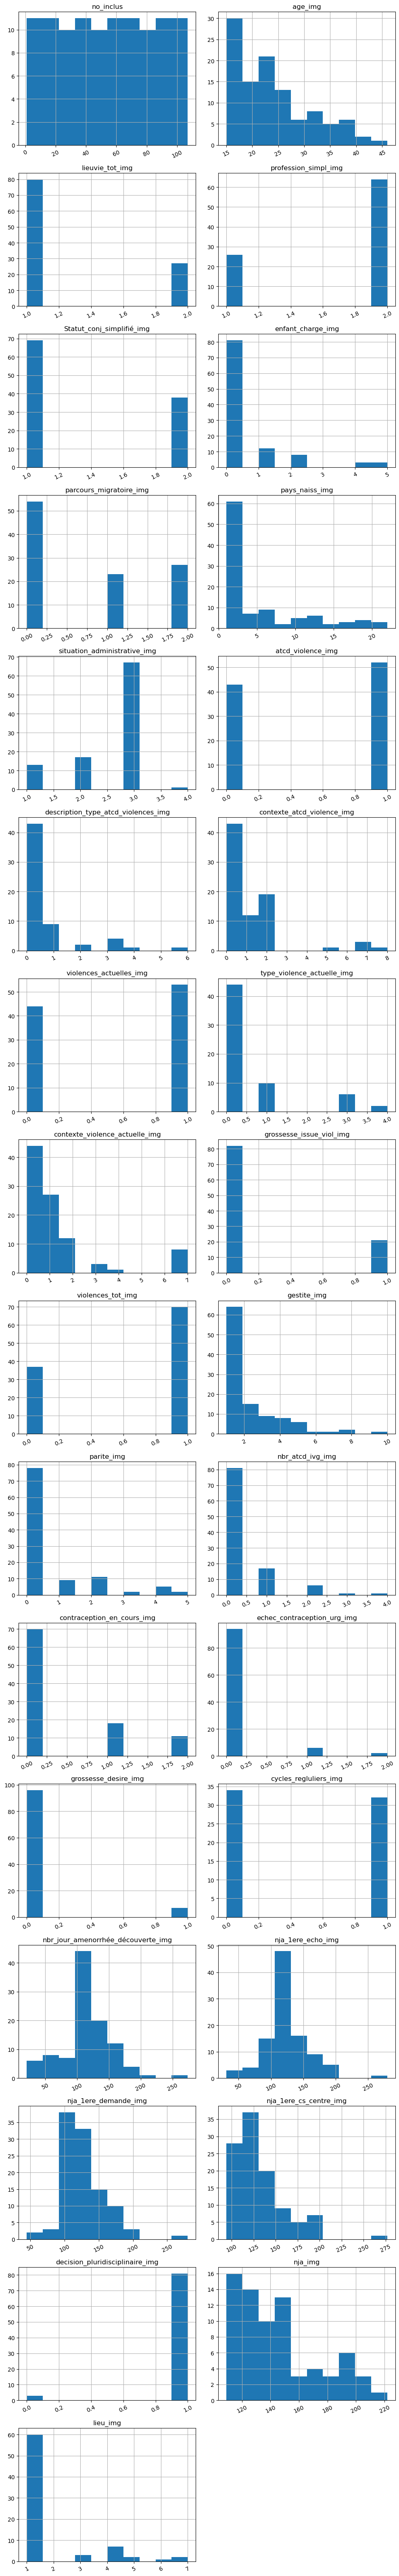

In [28]:
# Colonnes numériques
cols = df_img.select_dtypes(include='number').columns

# Supprimer les doublons sur ivg_no_inclus
df_unique = df_img.drop_duplicates(subset='no_inclus')

# Nombre de lignes à afficher (2 histogrammes par ligne)
n = len(cols)
rows = math.ceil(n / 2)

# Affichage des histogrammes
df_unique[cols].hist(layout=(rows, 2), figsize=(10, rows * 4), xrot=25)
plt.tight_layout()
plt.show()

In [29]:
# On enlève les doublons sur 'ivg_no_inclus' et garde le premier
df_img_unique = df_img.drop_duplicates(subset='no_inclus')

In [30]:
# Statistiques récapitulatives des caractéristiques numériques
df_img_unique.describe()

,no_inclus,age_img,lieuvie_tot_img,profession_simpl_img,Statut_conj_simplifié_img,enfant_charge_img,parcours_migratoire_img,pays_naiss_img,situation_administrative_img,atcd_violence_img,...,date_1ere_echo_img,nja_1ere_echo_img,date_1ere_demande_img,nja_1ere_demande_img,date_1ere_cs_centre_img,nja_1ere_cs_centre_img,decision_pluridisciplinaire_img,date_img,nja_img,lieu_img
count,107.000000,107.000000,107.000000,90.000000,107.000000,107.000000,104.000000,102.000000,98.000000,95.000000,...,101,101.000000,105,105.000000,107,107.000000,84.000000,73,73.000000,75.000000
mean,54.000000,24.009346,1.252336,1.711111,1.355140,0.514019,0.740385,5.088235,2.571429,0.547368,...,2020-07-03 08:04:45.148514816,122.673267,2020-07-10 08:41:08.571428608,126.980952,2020-07-04 14:21:18.504673024,132.504673,0.964286,2020-05-12 13:48:29.589041152,145.328767,1.693333
min,1.000000,15.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,...,2018-03-04 00:00:00,31.000000,2018-03-04 00:00:00,45.000000,2018-03-04 00:00:00,94.000000,0.000000,2018-03-14 00:00:00,109.000000,1.000000
25%,27.500000,18.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,2.000000,0.000000,...,2019-12-08 00:00:00,108.000000,2019-11-24 00:00:00,109.000000,2019-11-12 00:00:00,111.000000,1.000000,2019-09-26 00:00:00,123.000000,1.000000
50%,54.000000,23.000000,1.000000,2.000000,1.000000,0.000000,0.000000,1.000000,3.000000,1.000000,...,2020-06-16 00:00:00,118.000000,2020-06-16 00:00:00,119.000000,2020-06-22 00:00:00,123.000000,1.000000,2020-05-18 00:00:00,136.000000,1.000000
75%,80.500000,28.000000,1.500000,2.000000,2.000000,0.000000,2.000000,7.000000,3.000000,1.000000,...,2021-04-14 00:00:00,135.000000,2021-04-20 00:00:00,140.000000,2021-04-17 12:00:00,142.500000,1.000000,2021-02-01 00:00:00,159.000000,1.000000
max,107.000000,46.000000,2.000000,2.000000,2.000000,5.000000,2.000000,22.000000,4.000000,1.000000,...,2022-02-17 00:00:00,280.000000,2022-02-17 00:00:00,280.000000,2022-02-24 00:00:00,277.000000,1.000000,2022-02-24 00:00:00,222.000000,7.000000
std,31.032241,7.246984,0.436397,0.455785,0.480808,1.144012,0.847557,5.913741,0.732177,0.500392,...,NaN,34.344755,NaN,31.856041,NaN,29.340993,0.186691,NaN,29.516500,1.506502


In [31]:
# Statistiques récapitulatives des caractéristiques catégoriques
df_img_unique.describe(include='object')

,terme_decouverte_grossesse_img,terme_1ere_echo_img,terme_1ere_demande_img,terme_1ere_cs_centre_img,terme_img,parcours,img
count,103,101,105,107,73,107,107
unique,66,55,56,59,44,4,5
top,15SA+4j,15SA+4j,20SA+0j,20SA+0j,18SA+5j,oui,oui
freq,6,7,6,8,4,81,75


### 7) Analyse des corrélations

In [32]:
# Calcul de la matrice de corrélation
corrs = df_img_unique.select_dtypes(include='number').corr()
corrs

,no_inclus,age_img,lieuvie_tot_img,profession_simpl_img,Statut_conj_simplifié_img,enfant_charge_img,parcours_migratoire_img,pays_naiss_img,situation_administrative_img,atcd_violence_img,...,echec_contraception_urg_img,grossesse_desire_img,cycles_regluliers_img,nbr_jour_amenorrhée_découverte_img,nja_1ere_echo_img,nja_1ere_demande_img,nja_1ere_cs_centre_img,decision_pluridisciplinaire_img,nja_img,lieu_img
no_inclus,1.000000,0.021058,0.082898,0.224989,0.025923,0.008504,-0.015099,0.209276,-0.118102,0.169989,...,-0.128569,-0.092215,-0.106665,0.164364,0.105540,0.120833,0.133586,-0.087813,0.121021,0.359751
age_img,0.021058,1.000000,0.020128,-0.278823,0.172317,0.563816,0.300667,0.330537,-0.219413,0.063700,...,-0.078686,0.201508,0.206103,-0.060501,-0.118528,-0.010770,-0.059918,0.136567,-0.010356,0.057262
lieuvie_tot_img,0.082898,0.020128,1.000000,0.077325,-0.206319,-0.092187,0.072398,0.216776,-0.153478,0.188016,...,-0.034570,-0.156911,-0.132587,0.012182,0.141476,-0.003083,0.008380,0.118173,0.035408,0.034183
profession_simpl_img,0.224989,-0.278823,0.077325,1.000000,-0.141119,-0.204583,-0.094205,-0.030553,-0.069873,-0.103005,...,-0.102628,-0.019201,-0.166856,0.114847,0.195540,-0.044089,-0.043664,-0.131559,0.039259,0.030730
Statut_conj_simplifié_img,0.025923,0.172317,-0.206319,-0.141119,1.000000,0.110921,-0.104634,-0.094476,0.128685,-0.115163,...,-0.202666,0.113323,0.148964,-0.019662,-0.083531,-0.137270,-0.179337,-0.004906,-0.320956,0.227020
enfant_charge_img,0.008504,0.563816,-0.092187,-0.204583,0.110921,1.000000,0.268623,0.088854,-0.085423,0.014975,...,-0.009274,0.075491,0.272031,-0.060022,-0.151063,0.004458,-0.053051,0.086993,0.012049,-0.022923
parcours_migratoire_img,-0.015099,0.300667,0.072398,-0.094205,-0.104634,0.268623,1.000000,0.639028,-0.633021,0.093527,...,-0.018464,-0.045249,0.084345,0.016627,0.007075,0.028983,0.001844,0.096404,0.151277,-0.134313
pays_naiss_img,0.209276,0.330537,0.216776,-0.030553,-0.094476,0.088854,0.639028,1.000000,-0.606283,0.175434,...,0.024473,-0.035363,0.008891,0.040597,0.017011,-0.013511,-0.009091,0.117878,0.156943,0.007080
situation_administrative_img,-0.118102,-0.219413,-0.153478,-0.069873,0.128685,-0.085423,-0.633021,-0.606283,1.000000,-0.121595,...,0.025377,0.105128,-0.084549,-0.066451,-0.023138,0.084790,0.117392,-0.118462,0.039645,0.159029
atcd_violence_img,0.169989,0.063700,0.188016,-0.103005,-0.115163,0.014975,0.093527,0.175434,-0.121595,1.000000,...,0.072585,0.085887,-0.074477,-0.023479,0.071386,0.059111,0.090844,0.102582,0.125853,-0.187738


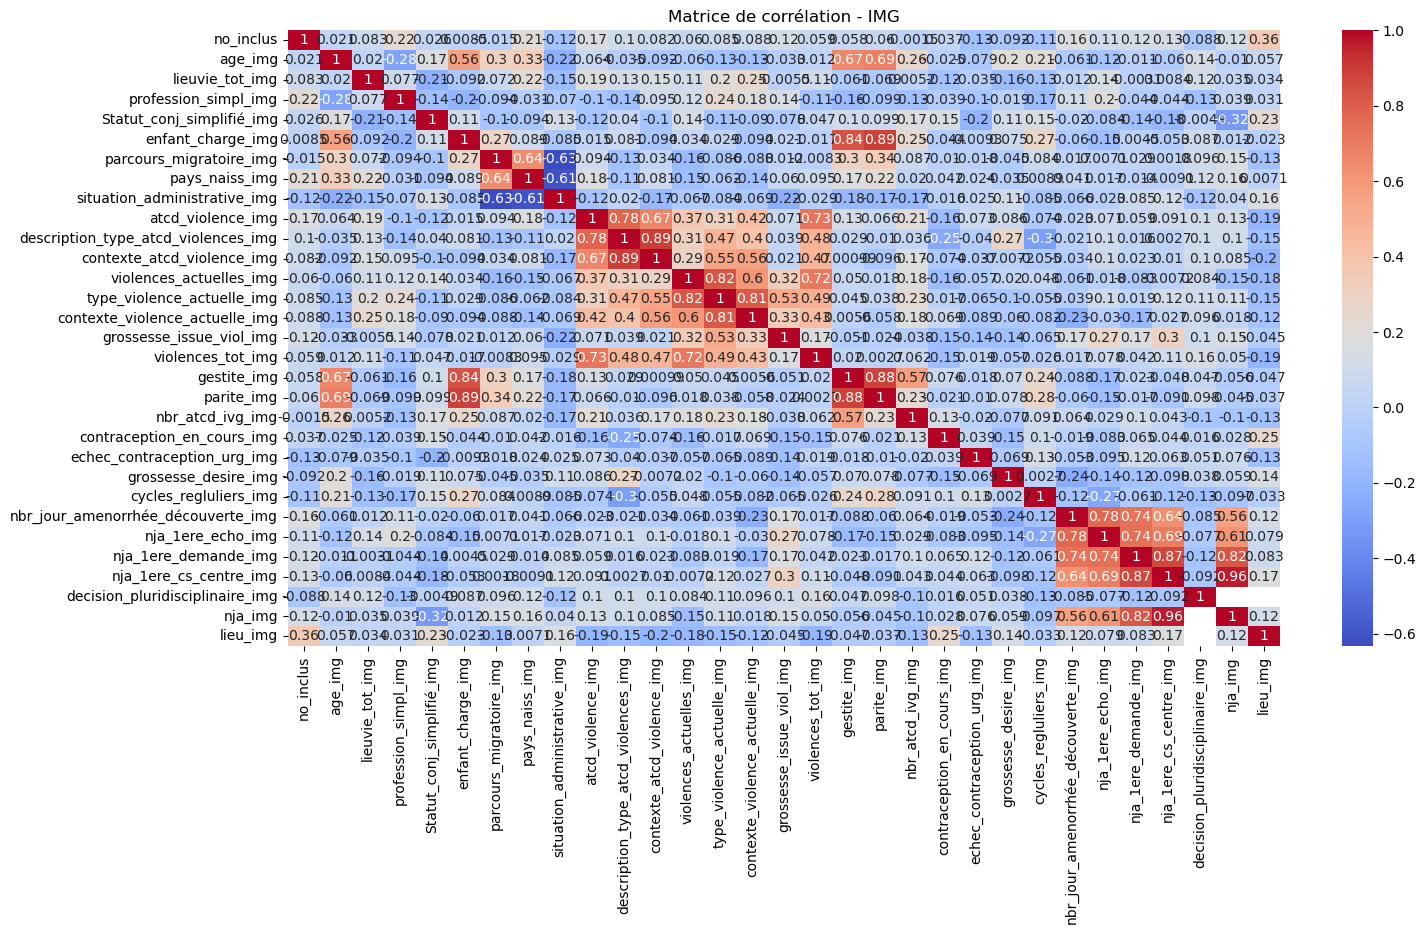

In [33]:
#Affichage de la heatmap
plt.figure(figsize=(16, 8))
sns.heatmap(corrs, annot=True, cmap='coolwarm')
plt.title("Matrice de corrélation - IMG")
plt.show()

In [34]:
# Filtrage des corrélations supérieures à 0.5 (hors diagonale)
high_corr = corrs.where(np.triu(np.ones(corrs.shape), k=1).astype(bool))
high_corr_filtered = high_corr[(high_corr.abs() > 0.45)]

# Récupération des couples de variables concernées
result = high_corr_filtered.stack().reset_index()
result.columns = ['Variable 1', 'Variable 2', 'Corrélation']

# Affichage
print(result)

                             Variable 1                           Variable 2  \
0                               age_img                    enfant_charge_img   
1                               age_img                          gestite_img   
2                               age_img                           parite_img   
3                     enfant_charge_img                          gestite_img   
4                     enfant_charge_img                           parite_img   
5               parcours_migratoire_img                       pays_naiss_img   
6               parcours_migratoire_img         situation_administrative_img   
7                        pays_naiss_img         situation_administrative_img   
8                     atcd_violence_img  description_type_atcd_violences_img   
9                     atcd_violence_img           contexte_atcd_violence_img   
10                    atcd_violence_img                    violences_tot_img   
11  description_type_atcd_violences_img 